**ICS 3202: Artificial Intelligence**

Practical Exercise 3: Designing a Searching Agent

**Group Members**

Fabunmi, Eniola Faithfulness 167925 <br>
Maina, Tiffany Wanjiru 189592 <br>
Ogwayo, Emma Awuor 189923 <br>

**1. Exercise Overview**

In Part 1 of this exercise, we represented Kenya's highway network using a directed graph, showing the towns and the distances between them. In this part, we use that same graph to implement Uniform Cost Search (UCS) in Python. The aim is to show how the self-driving trailer searches for a route from Nairobi (starting point) to Kisumu (destination) and finds the route with the lowest total distance.

**2. Uniform Cost Search (UCS)**

Uniform Cost Search is a search algorithm that always explores the available path with the lowest total cost first. It uses a priority queue to keep track of the possible paths, with the path having the smallest accumulated cost being selected first.

In our case, the cost is the distance travelled in kilometres. This means that the algorithm considers the total distance from Nairobi rather than just looking at the distance to the next town. It continues exploring the available paths until Kisumu is removed from the priority queue. This ensures that the route returned is the one with the lowest total distance.

**3. Directed Graph of Kenya's Highway Network**

The graph below is the same one developed in Part 1 of the exercise. Each town is represented by a node, while the arrows show the road connections between towns. The distances labelled on the arrows represent the cost of travelling between the towns in kilometres. These are the distances that will be used by our UCS algorithm.

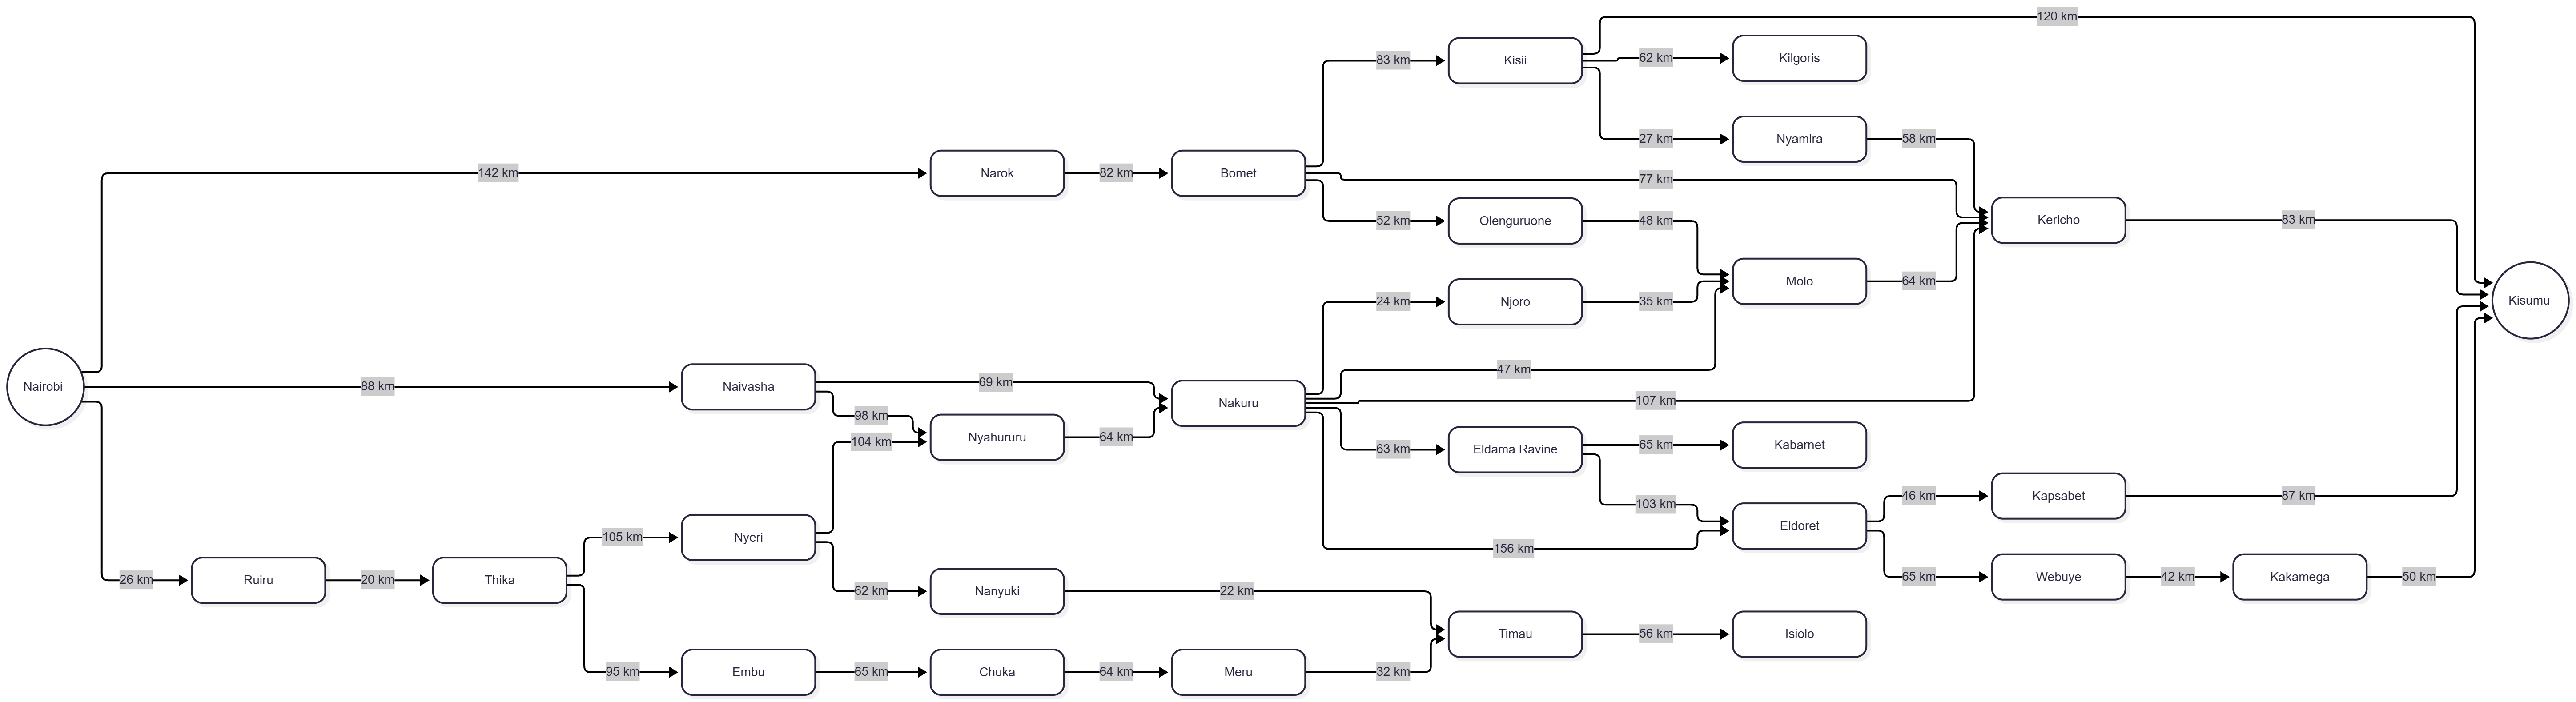

**4. How the Code Works**

We first represented the highway network using a Python dictionary called `highway_graph`, showing each town, its connected towns and the distance between them.

We then used `heapq` to create a priority queue that keeps the paths in order of their accumulated costs. At each step, the algorithm selects the town with the lowest cost, explores its neighbouring towns and adds their distances to the current cost. A `visited` set helps avoid exploring the same town more than once. The search traversal shows the order in which the towns are explored.

The algorithm only stops when Kisumu is selected from the priority queue, rather than when it is first added. It then returns the optimal path and its total distance.

In [5]:
import heapq

def uniform_cost_search(graph, start, goal):
    # Priority queue stores tuples of: (accumulated_cost, current_town, path_taken)
    queue = [(0, start, [start])]

    # Track expanded towns to avoid redundant loops
    visited = set()

    # Record the step-by-step expansion history for traversal demonstration
    traversal = []

    while queue:
        # Always expand the node with the lowest cumulative path cost g(n)
        cost, current_node, path = heapq.heappop(queue)

        # Skip if the town has already been expanded
        if current_node in visited:
            continue

        visited.add(current_node)

        # Record the town, cumulative cost, and full path at the moment of expansion
        traversal.append((current_node, cost, path))

        # Goal test: delayed termination until the goal node is officially popped
        if current_node == goal:
            return cost, path, traversal

        # Explore outgoing highway connections
        for neighbor, distance in graph.get(current_node, {}).items():
            if neighbor not in visited:
                total_cost = cost + distance
                heapq.heappush(queue, (total_cost, neighbor, path + [neighbor]))

    return float('inf'), [], traversal


# Directed Graph of Kenya's Highway Network (Step costs in km)
highway_graph = {
    'Nairobi': {'Ruiru': 26, 'Naivasha': 88, 'Narok': 142},
    'Ruiru': {'Thika': 20},
    'Thika': {'Nyeri': 105, 'Embu': 95},
    'Embu': {'Chuka': 65},
    'Chuka': {'Meru': 64},
    'Meru': {'Timau': 32},
    'Nyeri': {'Nanyuki': 62, 'Nyahururu': 104},
    'Nanyuki': {'Timau': 22},
    'Timau': {'Isiolo': 56},
    'Nyahururu': {'Nakuru': 64},
    'Naivasha': {'Nakuru': 69, 'Nyahururu': 98},
    'Nakuru': {'Njoro': 24, 'Molo': 47, 'Kericho': 107, 'Eldama Ravine': 63, 'Eldoret': 156},
    'Njoro': {'Molo': 35},
    'Molo': {'Kericho': 64},
    'Eldama Ravine': {'Kabarnet': 65, 'Eldoret': 103},
    'Eldoret': {'Kapsabet': 46, 'Webuye': 65},
    'Kapsabet': {'Kisumu': 87},
    'Webuye': {'Kakamega': 42},
    'Kakamega': {'Kisumu': 50},
    'Narok': {'Bomet': 82},
    'Bomet': {'Olenguruone': 52, 'Kericho': 77, 'Kisii': 83},
    'Olenguruone': {'Molo': 48},
    'Kisii': {'Kilgoris': 62, 'Nyamira': 27, 'Kisumu': 120},
    'Nyamira': {'Kericho': 58},
    'Kericho': {'Kisumu': 83},
    'Kisumu': {}
}

# Execute Uniform Cost Search
start_state = 'Nairobi'
goal_state = 'Kisumu'

optimal_cost, optimal_path, traversal = uniform_cost_search(
    highway_graph, start_state, goal_state
)

# This will display the results & the step by step Traversal
print("=" * 80)
print("UNIFORM COST SEARCH - SELF-DRIVING TRAILER TRAVERSAL")
print("=" * 80)
print(f"Start State : {start_state}")
print(f"Goal State  : {goal_state}")
print("-" * 80)

print("\nSEARCH TRAVERSAL (Order of Node Expansions)")
print("-" * 80)
for step, (town, cost, path) in enumerate(traversal, start=1):
    path_str = ' -> '.join(path)
    print(f"Step {step:<2} | Pop: {town:<15} | Cost: {cost:<3} km | Path: {path_str}")

print("-" * 80)

if optimal_path:
    print("\nFINAL OPTIMAL RESULT")
    print("-" * 80)
    print(f"Optimal Path : {' -> '.join(optimal_path)}")
    print(f"Total Cost   : {optimal_cost} km")
else:
    print("No route found to destination.")

UNIFORM COST SEARCH - SELF-DRIVING TRAILER TRAVERSAL
Start State : Nairobi
Goal State  : Kisumu
--------------------------------------------------------------------------------

SEARCH TRAVERSAL (Order of Node Expansions)
--------------------------------------------------------------------------------
Step 1  | Pop: Nairobi         | Cost: 0   km | Path: Nairobi
Step 2  | Pop: Ruiru           | Cost: 26  km | Path: Nairobi -> Ruiru
Step 3  | Pop: Thika           | Cost: 46  km | Path: Nairobi -> Ruiru -> Thika
Step 4  | Pop: Naivasha        | Cost: 88  km | Path: Nairobi -> Naivasha
Step 5  | Pop: Embu            | Cost: 141 km | Path: Nairobi -> Ruiru -> Thika -> Embu
Step 6  | Pop: Narok           | Cost: 142 km | Path: Nairobi -> Narok
Step 7  | Pop: Nyeri           | Cost: 151 km | Path: Nairobi -> Ruiru -> Thika -> Nyeri
Step 8  | Pop: Nakuru          | Cost: 157 km | Path: Nairobi -> Naivasha -> Nakuru
Step 9  | Pop: Njoro           | Cost: 181 km | Path: Nairobi -> Naivasha -> N